In [12]:
#Now, we will illustrate mixture model by mixing some distribution.
import numpy as np
def normal_distribution(x,expected, variance):
    denominator_1 = variance* np.sqrt(2*np.pi)
    numerator_1 = (x - expected)**2
    denominator_2 = 2*variance**2
    return (1/denominator_1)*np.exp(- numerator_1/denominator_2) 


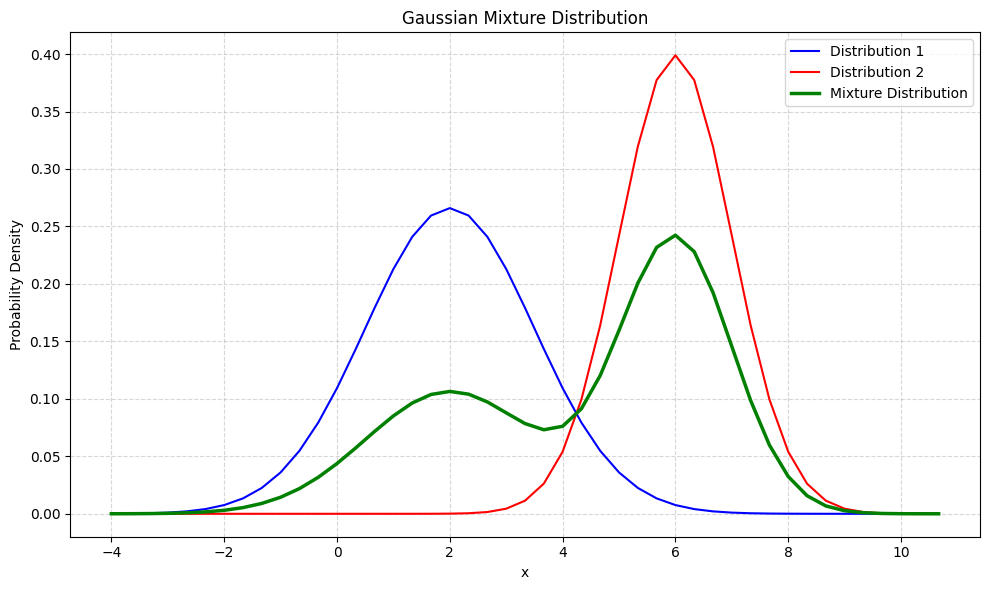

In [6]:
point_of_distribution_1 = []
point_of_distribution_2 = []
mixture = []
weights = [0.4, 0.6]
expected = [2, 6]
variance = [1.5 , 1]

for i in range(-12, 33):
    x = i/3
    y_1 = normal_distribution(x, expected[0], variance[0])
    point_of_distribution_1.append((x,y_1))
    y_2 = normal_distribution(x,expected[1], variance[1])
    point_of_distribution_2.append((x, y_2))
    y_mixed = y_1*weights[0]+y_2*weights[1]
    mixture.append((x,y_mixed))

#Plot each distribution
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

# Extract x and y values
x_1, y_1 = zip(*point_of_distribution_1)
x_2, y_2 = zip(*point_of_distribution_2)
x_m, y_m = zip(*mixture)

# Plot all distributions on the same figure
plt.figure(figsize=(10, 6))

plt.plot(x_1, y_1, color='blue', label='Distribution 1')
plt.plot(x_2, y_2, color='red', label='Distribution 2')
plt.plot(x_m, y_m, color='green', linewidth=2.5, label='Mixture Distribution')

plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Gaussian Mixture Distribution')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [34]:
import numpy as np
import random as rd

# Gaussian probability density function
# var is the variance (sigma^2)
def normal_distribution(x, expected, variance):
    variance = max(float(variance), 1e-10)
    return (
        1 / np.sqrt(2 * np.pi * variance)
        * np.exp(-(np.asarray(x) - expected)**2 / (2 * variance))
    )

# Generate data
samples = np.arange(-3.0, 10.0, 0.1)

weights = [0.4, 0.6]
expected = [2, 6]
variance = [1.5, 1.0]

density = (
    weights[0] * normal_distribution(samples, expected[0], variance[0])
    + weights[1] * normal_distribution(samples, expected[1], variance[1])
)

# Normalize density to use as sampling probabilities
density = density / density.sum()

generated_data = np.array(
    rd.choices(samples.tolist(), weights=density.tolist(), k=1000)
)

# E-step
def E_steps(x, mu, var, w):
    x = np.asarray(x).reshape(-1)

    component_1 = normal_distribution(x, mu[0], var[0]) * w[0]
    component_2 = normal_distribution(x, mu[1], var[1]) * w[1]

    total = component_1 + component_2
    total = np.maximum(total, 1e-300)

    responsibility_1 = component_1 / total
    responsibility_2 = component_2 / total

    return np.column_stack((responsibility_1, responsibility_2))

# M-step
def M_steps(x, responsibility):
    x = np.asarray(x).reshape(-1)
    N = len(x)

    new_expected = []
    new_variance = []
    new_weight = []

    for i in range(2):
        r = responsibility[:, i]
        effective_N = r.sum()
        effective_N = max(effective_N, 1e-10)

        mu_i = np.sum(r * x) / effective_N
        var_i = np.sum(r * (x - mu_i)**2) / effective_N
        weight_i = effective_N / N

        new_expected.append(mu_i)
        new_variance.append(max(var_i, 1e-10))
        new_weight.append(weight_i)

    return new_expected, new_variance, new_weight

# EM algorithm
threshold = 1e-9
max_loops = 500

avg_mu = np.average(generated_data)
avg_var = np.var(generated_data)
mu = [1, 10]
var = [1, 10]
w = [0.5, 0.5]

print(f"Initial: mu={mu}, var={var}, w={w}")

for loop in range(max_loops):
    responsibility = E_steps(generated_data, mu, var, w)
    new_mu, new_var, new_w = M_steps(generated_data, responsibility)

    dif_mu = np.mean(np.abs(np.array(new_mu) - mu))
    dif_var = np.mean(np.abs(np.array(new_var) - var))
    dif_weight = np.mean(np.abs(np.array(new_w) - w))

    mu, var, w = new_mu, new_var, new_w

    print(
        f"Loop {loop + 1}: "
        f"mu={np.round(mu, 4)}, "
        f"var={np.round(var, 4)}, "
        f"w={np.round(w, 4)}"
    )

    if max(dif_mu, dif_var, dif_weight) < threshold:
        print("Converged!")
        break
else:
    print("Reached maximum iterations.")
print(responsibility)


Initial: mu=[1, 10], var=[1, 10], w=[0.5, 0.5]
Loop 1: mu=[1.8365 5.8162], var=[1.1528 1.4386], w=[0.3742 0.6258]
Loop 2: mu=[1.8683 5.852 ], var=[1.2034 1.345 ], w=[0.3828 0.6172]
Loop 3: mu=[1.9023 5.8838], var=[1.2434 1.2801], w=[0.391 0.609]
Loop 4: mu=[1.9321 5.9095], var=[1.2815 1.23  ], w=[0.3979 0.6021]
Loop 5: mu=[1.9579 5.9304], var=[1.3166 1.1912], w=[0.4036 0.5964]
Loop 6: mu=[1.9799 5.9473], var=[1.3483 1.1609], w=[0.4084 0.5916]
Loop 7: mu=[1.9986 5.961 ], var=[1.3764 1.1372], w=[0.4124 0.5876]
Loop 8: mu=[2.0146 5.9723], var=[1.401  1.1183], w=[0.4157 0.5843]
Loop 9: mu=[2.0281 5.9815], var=[1.4224 1.1032], w=[0.4185 0.5815]
Loop 10: mu=[2.0395 5.9892], var=[1.4409 1.0911], w=[0.4208 0.5792]
Loop 11: mu=[2.0492 5.9955], var=[1.4568 1.0812], w=[0.4228 0.5772]
Loop 12: mu=[2.0574 6.0007], var=[1.4705 1.0731], w=[0.4244 0.5756]
Loop 13: mu=[2.0643 6.0051], var=[1.4822 1.0664], w=[0.4258 0.5742]
Loop 14: mu=[2.0702 6.0088], var=[1.4922 1.0609], w=[0.427 0.573]
Loop 15: mu=[2

In [35]:
percent = []
for res in responsibility:
    percent.append(np.argmax(res))
percent

[np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.in

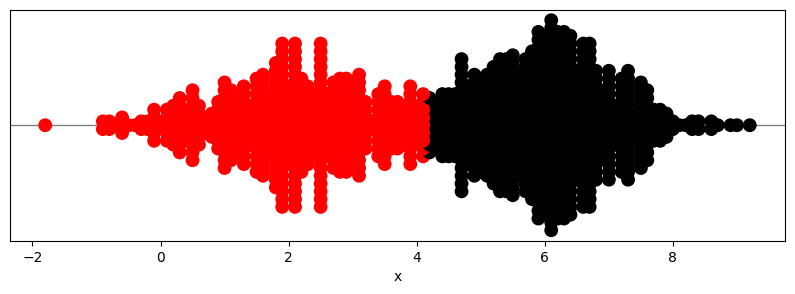

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

points = generated_data
mangmau = percent

colors = ['red' if c == 0 else 'black' for c in mangmau]

# Phân nhóm các điểm có cùng tọa độ x
groups = defaultdict(list)
for i, x in enumerate(points):
    groups[x].append(i)

# Rải điểm chồng nhau theo trục Oy
y_positions = np.zeros(len(points))

for indices in groups.values():
    n = len(indices)
    offsets = (np.arange(n) - (n - 1) / 2) * 0.08
    for idx, offset in zip(indices, offsets):
        y_positions[idx] = offset

plt.figure(figsize=(10, 3))
plt.scatter(points, y_positions, c=colors, s=80, zorder=3)
plt.axhline(0, color='gray', linewidth=1)
plt.yticks([])
plt.xlabel('x')
plt.show()